# P3 이론: 합성곱 신경망과 컴퓨터 비전

**감사의 글**

아래 내용은 프랑소와 숄레의 
[Deep Learning with Python(3판)](https://github.com/fchollet/deep-learning-with-python-notebooks)의 
소스코드 내용을 참고해서 작성되었습니다.
자료를 공개한 저자에게 진심어린 감사를 전합니다.

**주요 내용**

핵심 질문: 신경망은 어떻게 이미지에 포함된 물체의 모양과 위치를 학습할까?

CNN(합성곱 신경망)의 **합성곱 연산**(`Conv2D`)을 중심으로, 필터가 이미지의 국소 영역에서 값을 계산하고 특성맵을 만드는 과정을 살펴본다. 이어서 풀링, 이미지 분류, 데이터 증식, 전이 학습, 객체 탐지, Xception 구조로 확장한다.

학습 목표는 다음과 같다.

1. `Conv2D`의 입력·필터·출력 특성맵을 설명하고, 작은 배열에서 출력값을 직접 계산한다.
2. **필터 수, 입력 채널, 패딩, 보폭**으로 출력 크기와 파라미터 수를 설명한다.
3. CNN의 특성 추출이 이미지 분류, 전이 학습, 객체 탐지로 연결되는 방식을 이해한다.
4. 잔차 연결·배치 정규화·채널 분리 합성곱의 역할을 구분한다.

본문 설명과 계산 예제는 짧게 실행할 수 있도록 구성했다. 실제 모델 훈련은 P3 실습에서 수행한다.

## 이미지 분류에 CNN이 필요한 이유

### 같은 숫자라도 픽셀 위치가 달라진다면?

MNIST 손글씨 이미지는 가로 28픽셀, 세로 28픽셀로 이루어져 있다. 이미지를 펼치면 **784개의 수치형 특성**으로 표현할 수 있다. 다층 퍼셉트론(MLP)은 이 784개 값을 입력으로 받을 수 있지만, 펼쳐진 벡터만으로는 **어떤 픽셀이 서로 이웃하는지**를 직접 드러내지 않는다.

CNN은 입력을 `(높이, 너비, 채널)` 형태로 유지하며, 가까이 모여 있는 픽셀의 조합에서 유용한 패턴을 찾는다.

| 이미지 | 한 샘플의 모양 | 채널 수 |
|---|---|---:|
| MNIST 손글씨(흑백) | `(28, 28, 1)` | 1 |
| CIFAR-10 컬러 이미지 | `(32, 32, 3)` | 3 |

### Keras CNN 분류 모델 만들기

아래 `mnist_cnn_model`은 **합성곱 층 → 맥스 풀링 층**을 반복한 다음 분류 출력층을 연결하는 모델이다.
이미지의 공간 정보를 보존하는 것이 MLP와 가장 큰 차이다.

```python
inputs = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, padding="same", activation="relu", name="first_conv")(inputs)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation="softmax")(x)

mnist_cnn_model = keras.Model(inputs, outputs)
```

위 코드는 Keras의 **함수형 API**(Functional API)를 이용하여 CNN 모델을 정의하는 방식이다. 

- `keras.Input()`으로 입력층을 정의한 다음, 각 층의 출력 텐서를 다음 층의 입력으로 전달하는 방식으로 신경망을 구성한다. 이때 `layers.Conv2D(...)(x)`와 같이 층을 생성한 후 입력 텐서에 적용하여 층들을 연결한다. 
- 이후 `keras.Model(inputs, outputs)`를 이용해 입력 텐서와 출력 텐서를 지정하면 전체 신경망 모델이 완성된다. 

함수형 API는 층들이 연결되는 과정을 명시적으로 표현할 수 있으며, 단순한 순차 구조뿐 아니라 여러 입력과 출력, 분기 및 병합이 있는 복잡한 신경망도 구성할 수 있다는 장점이 있다.

### Dense와 Conv2D가 보는 입력 범위

- **Dense:** 출력 유닛 하나가 입력의 **전체 특성**을 사용하여 가중합을 계산한다.
- **Conv2D:** 출력의 **각 위치**를 계산할 때 **필터**가 덮고 있는 **국소 영역**에 대해서만 가중치 곱이 사용한다. 그리고 **같은 필터 가중치** 적용을 필터를 이동시키며 다른 위치에서도 반복한다.

즉, CNN은 이미지를 작은 부분으로 나누어 따로 훈련하는 모델이 아니다. **한 필터를 공유하면서 이미지 전역을 훑는 모델**이다.

## Conv2D: 하나의 출력값은 어떻게 계산할까?

### 필터(kernel)가 보는 영역

`Conv2D`의 `kernel_size=3`은 필터가 한 번에 보는 **높이 3, 너비 3**의 공간을 뜻한다. 흑백 이미지라면 3×3의 **9개 픽셀**과 9개 가중치를 각각 곱해서 더하고, 편향을 더하여 출력값 하나를 만든다.

아래에서는 픽셀마다 밝기가 조금씩 다르지만 오른쪽이 대체로 밝은 5×5 이미지와 **서로 다른 가중치를 갖는 3×3 필터**를 사용한다. 필터는 왼쪽 값에 음의 가중치, 오른쪽 값에 상대적으로 큰 양의 가중치를 주어 밝기 차이에 반응하도록 만든 간단한 예제다. 실제 CNN에서는 이런 가중치를 **모델 훈련 과정에서 학습**한다.

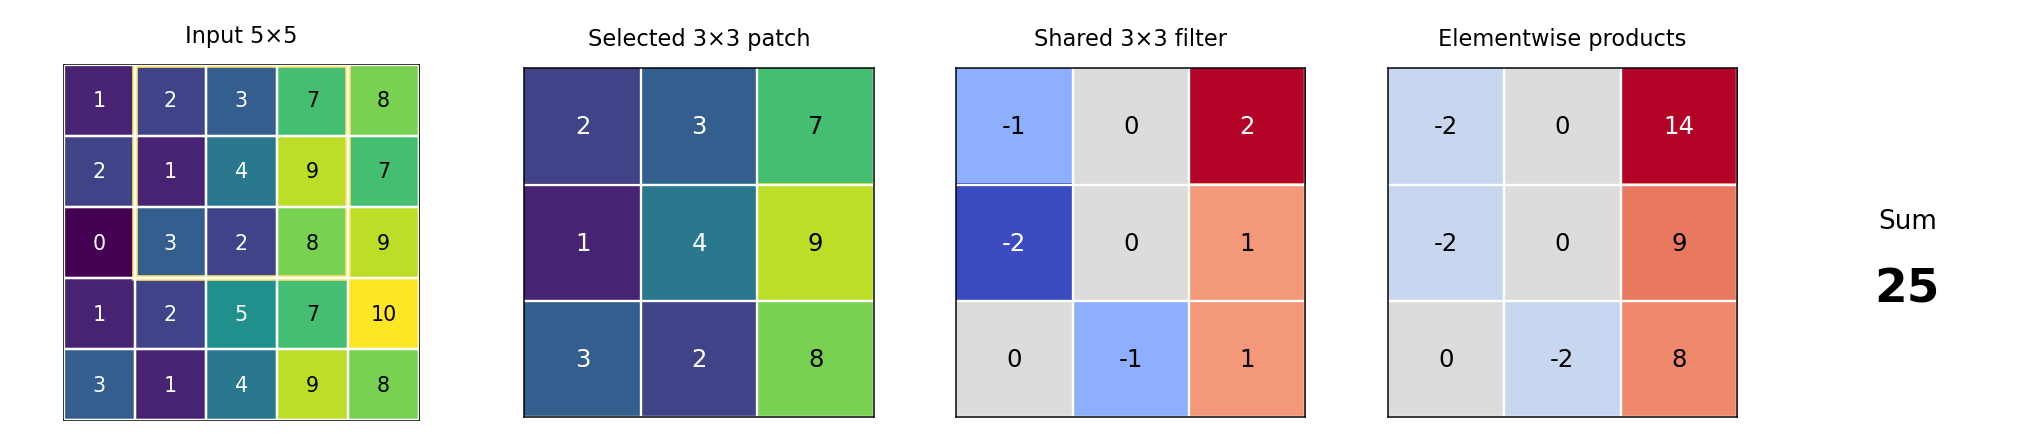

5x5 어레이에서 선택된 패치의 값과 필터 가중치를 원소별로 곱해서 더하는 결과는 다음과 같다.

$$
\begin{aligned}
z &= (2\times(-1)+3\times0+7\times2) \\
  &\quad +(1\times(-2)+4\times0+9\times1) \\
  &\quad +(3\times0+2\times(-1)+8\times1) \\
  &= 12+7+6=25.
\end{aligned}
$$

이 계산이 이미지의 다른 위치에서도 반복된다.

### 필터를 이동하면 출력 특성맵이 만들어진다

필터는 이미지의 한 위치에서 값 하나를 계산한 뒤 오른쪽으로 이동한다. 한 줄의 계산이 끝나면 아래로 이동한다. 모든 위치의 결과를 배열에 기록하면 **출력 특성맵**(output feature map)이 된다.

- 입력: `5×5`
- 필터: `3×3`
- 보폭: `1`
- 패딩: 없음(`valid`)
- 출력: `3×3`

왜 3×3이 될까? 필터의 왼쪽 위 시작 위치가 가로·세로 각각 **0, 1, 2**의 세 곳에만 올 수 있기 때문이다.

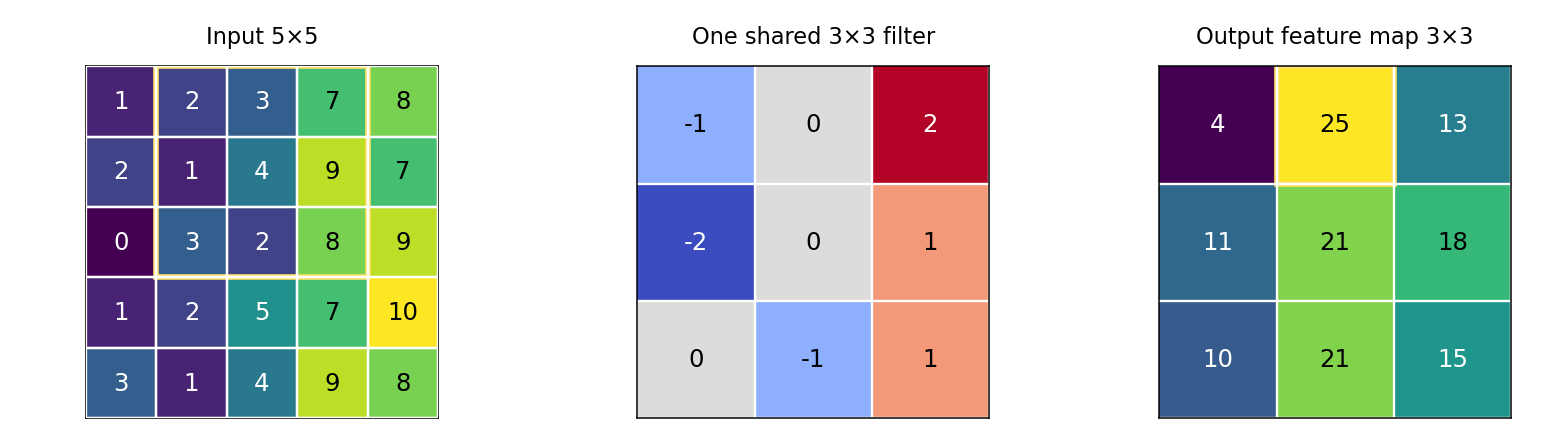

**관찰:** 같은 필터를 9개 위치에 적용해 9개의 출력값을 얻는다. 입력 패치의 숫자가 달라지기 때문에 **출력 특성맵의 값도 위치마다 다르다.** 노란 테두리는 앞에서 계산한 출력값 `25`의 위치를 나타낸다.

### 왜 같은 필터를 이미지 전체에 사용할까?

CNN의 합성곱층은 이미지의 **서로 다른 특징을 탐지하기 위해 여러 개의 필터**(filter)를 사용한다. 예를 들어 어떤 필터는 세로 방향의 경계를, 다른 필터는 가로 방향의 경계나 특정 질감에 반응하도록 학습될 수 있다. **각 필터는 서로 다른 가중치를 학습하며, 하나의 필터를 이미지 전체에 적용하여 하나의 특성맵(feature map)을 생성한다.**

이처럼 **하나의 필터가 이미지의 모든 위치에서 동일한 가중치를 사용하는 것**을 **가중치 공유**(weight sharing)라고 한다. 예를 들어 한 필터가 세로 방향 경계를 탐지하도록 학습됐다면, 이미지 왼쪽뿐 아니라 오른쪽에서도 **같은 가중치**를 사용해 비슷한 경계에 반응할 수 있다.

장점은 두 가지다.

1. 이미지의 위치마다 완전히 다른 가중치를 학습할 필요가 없어 **파라미터 수가 작다**.
2. 특징이 다른 위치로 이동하면 그에 대응하는 **특성맵의 반응 위치도 이동**한다.

즉, CNN은 **여러 필터를 사용하여 다양한 특징을 학습하면서도, 각 필터의 가중치를 이미지 전체에서 공유**함으로써 적은 파라미터로 효율적인 특징 추출을 수행한다.

## Conv2D: RGB 채널과 여러 필터

### RGB 입력에서는 필터도 3차원이다

컬러 이미지의 한 픽셀에는 보통 R·G·B 세 값이 있다. 따라서 `kernel_size=3`인 **필터 하나**는 공간 크기가 3×3이고 **깊이는 입력 채널 수 3**이다.

- 입력 텐서: `(높이, 너비, 3)`
- **필터 하나**의 가중치 모양: `(3, 3, 3)`
- 한 위치에서 계산하는 곱셈 수: `3×3×3 = 27`
- **한 필터의 출력:** 모든 채널의 계산을 합친 **출력 특성맵 한 장**

즉, RGB 이미지라고 해서 필터 하나가 반드시 출력 채널 세 개를 만드는 것은 아니다.

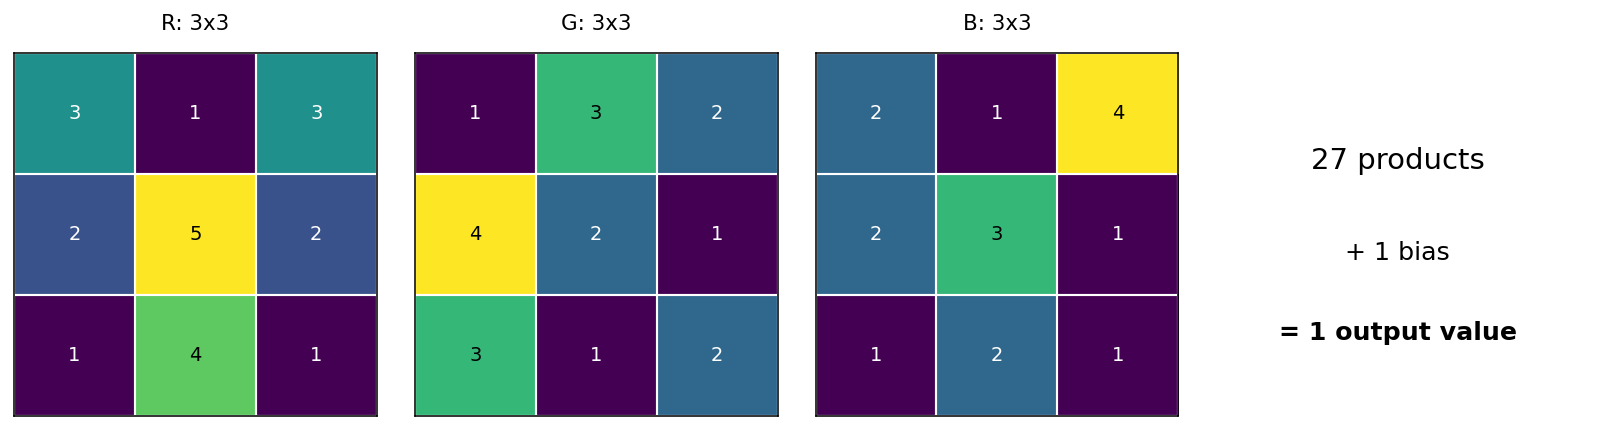

`(3, 3, 3)` 모양의 필터가 `(3, 3)` 모양의 필터와 동일한 방식으로 작동한다.

<div align="center"><img src="https://raw.githubusercontent.com/codingalzi/dlp2/master/jupyter-book/imgs/ch08-filter-product-1.jpg" width=550px></div>

<p><div style="text-align: center">&lt;그림 출처: <a href="https://www.oreilly.com/library/view/fundamentals-of-deep/9781492082170/">Fundamentals of Deep Learning(2판)</a>&gt;</div></p>

### 필터의 개수는 출력 채널 수를 결정한다

`layers.Conv2D(filters=32, kernel_size=3)`에서 `filters=32`는 서로 다른 필터를 **32개 학습**한다는 뜻이다. 필터 하나가 출력 특성맵 한 장을 만들므로 출력 채널 수가 32가 된다.

예를 들어, 입력이 `(8, 8, 3)`이고 `padding="valid"`, `strides=1`, 필터 수가 6개라면

- 필터 가중치 전체 모양: `(3, 3, 3, 6)` — Keras 기준
- 출력: `(6, 6, 6)`

각 출력 채널이 서로 다른 패턴에 반응할 수 있다. 어떤 필터는 세로 경계, 다른 필터는 가로 경계 등에 반응하도록 학습될 수 있지만, **필터의 의미가 미리 정해져 있는 것은 아니다**.

<div align="center"><img src="https://raw.githubusercontent.com/codingalzi/dlp2/master/jupyter-book/imgs/ch08-filter-product-2.jpg" style="width:700px;"></div>

<p><div style="text-align: center">&lt;그림 출처: <a href="https://www.oreilly.com/library/view/fundamentals-of-deep/9781492082170/">Fundamentals of Deep Learning(2판)</a>&gt;</div></p>

### Keras와 PyTorch의 채널 순서 비교

| 구분 | Keras 기본 형식 | PyTorch 기본 형식 |
|---|---|---|
| 한 이미지 | `(H, W, C)` | `(C, H, W)` |
| 배치 | `(N, H, W, C)` | `(N, C, H, W)` |

두 라이브러리의 **연산 원리와 출력 채널 수**는 같다. 다만 텐서의 축 순서가 다를 뿐이다.

## Conv2D: 패딩, 보폭, 출력 크기

### 보폭(stride)은 필터를 얼마나 움직일까?

`strides=1`은 필터를 한 칸씩 이동한다. `strides=2`는 두 칸씩 이동한다. 따라서 다른 조건이 같다면 보폭이 커질수록 **출력 특성맵의 공간 크기가 작아진다**.

### 패딩(padding)은 이미지 바깥을 어떻게 다룰까?

- `padding="valid"`: 이미지 바깥으로 필터가 나가지 않게 한다. 주변을 추가로 채우지 않는다.
- `padding="same"`: 출력 크기가 `ceil(입력 크기 / strides)`가 되도록 필요한 패딩을 추가한다. `strides=1`이면 공간 크기를 유지한다.

흔히 0을 추가하는 제로 패딩을 사용한다. **입력 채널 수나 필터 수를 바꾸는 설정은 아니다.**

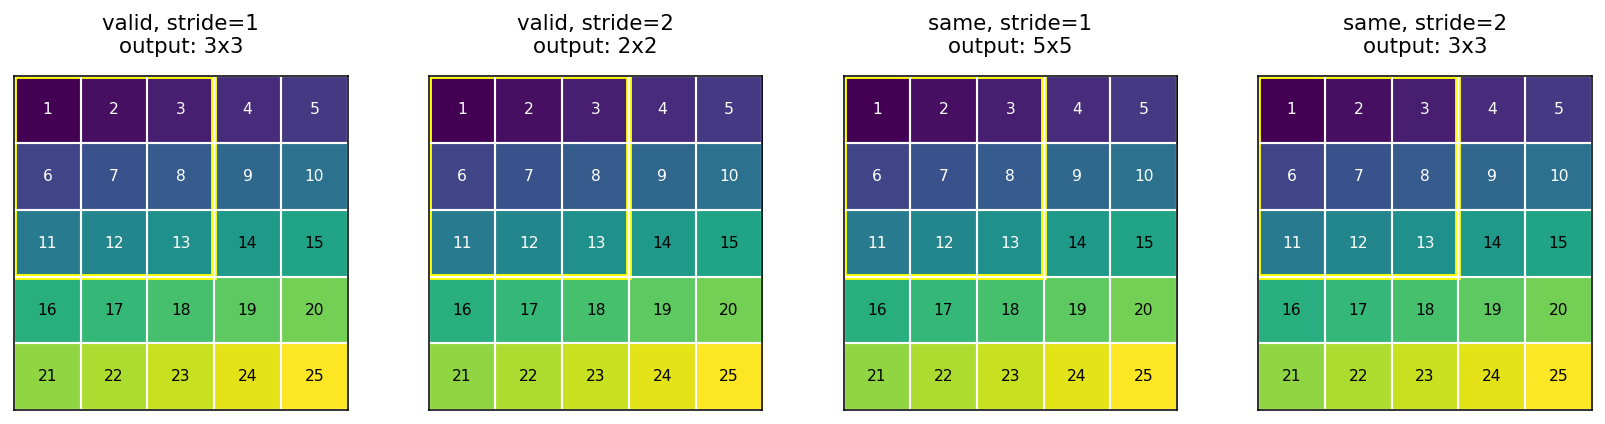

**관찰:** 네 경우 모두 입력과 필터 크기는 동일하지만, 패딩과 보폭에 따라 출력의 높이·너비가 달라진다. 노란 상자는 첫 번째 3×3 영역을 나타낸다.

### 출력 크기를 직접 계산해 보자

패딩이 없는 `valid`의 한 축 출력 크기는 다음과 같다.

$$
O_{\mathrm{valid}}=\left\lfloor\frac{N-K}{S}\right\rfloor+1
$$

- $N$: 입력의 높이 또는 너비
- $K$: 필터 크기(해당 축)
- $S$: 보폭

`same`의 출력 크기는 $\lceil N/S\rceil$이다. 여기서 $\lfloor\ \rfloor$는 내림, $\lceil\ \rceil$는 올림이다.

예를 들어 입력 `5×5`, 필터 `3×3`이면 `valid`/stride 1 → `3×3`, `valid`/stride 2 → `2×2`, `same`/stride 1 → `5×5`, `same`/stride 2 → `3×3`이다.

**참고:** 패딩과 보폭은 높이·너비에 각각 적용된다. 표에는 정사각형 입력과 필터를 가정했다.

### `padding="same"`이 항상 입력 크기를 유지할까?

아니다. **보폭이 1인 경우**에는 높이와 너비가 유지된다. 보폭이 2라면 `same`을 사용해도 출력 높이와 너비는 대략 절반으로 줄어든다.

- `(28,28,1)` → `Conv2D(32,3,padding="same",strides=1)` → `(28,28,32)`
- `(28,28,1)` → `Conv2D(32,3,padding="same",strides=2)` → `(14,14,32)`

**질문:** 보폭을 2로 바꾸면 **필터의 학습 파라미터 수**도 줄어들까? (아니야. 필터의 모양과 개수가 동일하면 파라미터 수는 같다.)

## Conv2D: 학습 파라미터는 얼마나 필요할까?

하나의 필터가 학습하는 가중치는 `커널 높이 × 커널 너비 × 입력 채널 수`개다. 필터가 $C_{out}$개라면 필터 가중치도 그만큼 늘어난다. 편향을 사용하면 필터마다 편향이 하나씩 추가된다. 아래 수식은 `use_bias=True`일 때이며, 편향이 없다면 `+1`을 제외한다.

$$
\mathrm{Params}_{\mathrm{Conv2D}} = (K_h \times K_w \times C_{\mathrm{in}} + 1) \times C_{\mathrm{out}}
$$

`use_bias=False`인 경우 `+1`을 제외한다.

예를 들어 **MNIST 입력 `(28,28,1)`에 `Conv2D(32,3)`**을 적용한다면 `3×3×1×32+32 = 320`개다. 이미지의 높이와 너비 자체가 파라미터 수 계산에 직접 곱해지지 않는 이유는 **필터 가중치를 모든 위치에서 공유**하기 때문이다.

### Dense와 직접 비교하기

입력의 **모든 784개 픽셀**을 출력 유닛 32개에 연결하는 `Dense(32)`는 `784×32+32 = 25,120`개의 파라미터를 갖는다. 같은 MNIST 입력에 `Conv2D(32,3)`을 적용하면 **320개**다.

이 비교는 출력 구조가 **서로 다른 두 층을 이해하기 위한 예시**이지, 파라미터 수만 보고 어느 층이 더 좋은 모델이라고 결론 내리기 위한 비교는 아니다. Dense 출력은 32개 값, Conv2D 출력은 여러 위치에 걸친 32개 **특성맵**이다.

## 풀링과 여러 합성곱 층의 결합

### 맥스 풀링은 무엇을 계산할까?

`MaxPooling2D(pool_size=2)`는 각 채널의 **2×2 영역에서 최댓값**을 하나 선택한다. 기본 보폭도 2이므로 일반적으로 높이·너비가 각각 절반이 된다.

풀링에는 필터 가중치를 학습하는 과정이 없다. 지정된 영역에서 최댓값만 선택할 뿐이다.

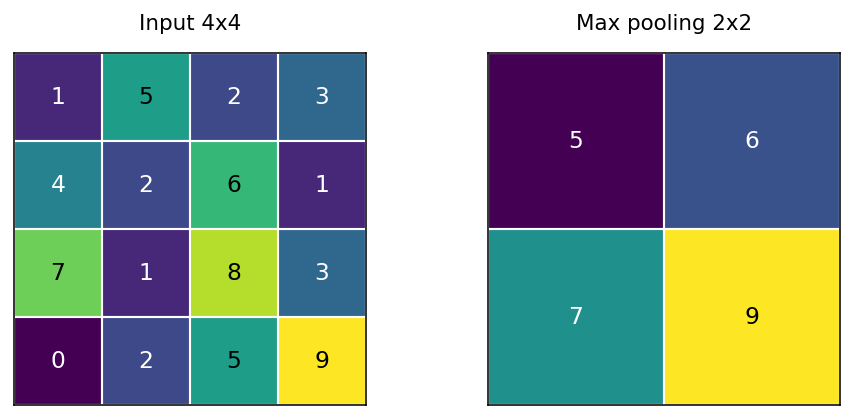

### 채널 수는 어떻게 변할까?

입력이 `(26,26,32)`이고 `MaxPooling2D(2)`를 적용하면 출력은 `(13,13,32)`이다. 높이·너비는 줄지만 **채널 수 32는 그대로**다.

반면 `Conv2D(64,3,padding="same")`을 적용하면 출력 채널 수가 **64**로 바뀐다. 즉, 합성곱은 **학습하는 필터의 수**로 채널을 정하고, 풀링은 각 채널의 공간 크기를 줄이는 역할을 한다.

### 합성곱층을 여러 번 쌓으면 무엇이 달라질까?

처음에는 작은 국소 패턴(예: 가로·세로 경계)에 반응하고, 층이 깊어지면서 앞선 층의 특성을 조합하여 **더 넓은 영역과 복잡한 형태**를 표현할 수 있다.

보폭 1인 3×3 합성곱을 연속 적용한다고 가정하면

- 첫 번째 층의 출력값 하나는 원본 입력의 **3×3** 영역에 의존한다.
- 두 번째 층의 출력값 하나는 원본 입력의 **5×5** 영역에 의존한다.
- 세 번째 층의 출력값 하나는 원본 입력의 **7×7** 영역에 의존한다.

이를 **수용 영역**(receptive field)이라고 한다. 패딩·보폭·풀링 등을 사용하면 실제 수용 영역의 증가 방식은 달라진다.

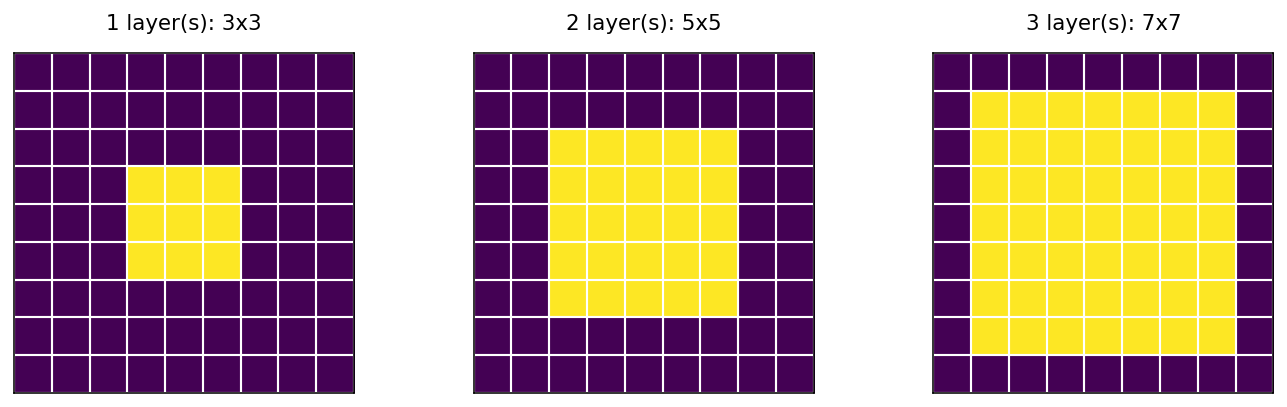

### Flatten과 GlobalAveragePooling2D

CNN의 마지막에는 각 채널의 정보를 분류층으로 전달한다. 대표적인 방법은 다음과 같다.

- `Flatten()`: `(H,W,C)`의 모든 값을 길이 `H×W×C`인 벡터로 펼친다.
- `GlobalAveragePooling2D()`: **채널마다 전체 공간의 평균을 계산**해 길이 `C`인 벡터를 만든다.

예를 들어 `(7,7,128)`의 출력이면 `Flatten()`은 6,272개 값, `GlobalAveragePooling2D()`는 128개 값을 제공한다. 두 연산 모두 자체적으로 학습할 가중치는 없지만, 뒤에 오는 분류층의 파라미터 수에는 큰 차이가 생길 수 있다.

## MNIST CNN을 층별로 읽어 보기

다음 모델은 `Conv2D` 세 개, `MaxPooling2D` 두 개, `GlobalAveragePooling2D`, `Dense`를 사용한다.

입력 `(28,28,1)`이 어떻게 변환되는지 **출력 크기와 채널 수**를 따라가 보자. 분류 문제이므로 마지막에 10개 클래스의 점수를 만들어 Softmax를 적용한다.

In [2]:
inputs = keras.Input(shape=(28, 28, 1))

x = layers.Conv2D(32, 3, padding='same', activation='relu')(inputs)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation='softmax')(x)

mnist_cnn_model = keras.Model(inputs, outputs)

mnist_cnn_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,962 (367.04 KB)

 Trainable params: 93,962 (367.04 KB)

 Non-trainable params: 0 (0.00 B)

**핵심:** 공간 크기는 주로 풀링과 보폭에 의해 바뀌고, 출력 채널 수는 **합성곱 필터 수**로 결정된다.

| 단계 | 출력 모양(배치 제외) | 중요한 변화 |
|---|---|---|
| 입력 | `28×28×1` | 흑백 이미지 |
| Conv2D(32,3,same) | `28×28×32` | 필터 32개 → 채널 32 |
| MaxPooling2D(2) | `14×14×32` | 공간 크기 절반 |
| Conv2D(64,3,same) | `14×14×64` | 채널 64 |
| MaxPooling2D(2) | `7×7×64` | 공간 크기 절반 |
| Conv2D(128,3,same) | `7×7×128` | 채널 128 |
| GlobalAveragePooling2D | `128` | 채널별 평균 |
| Dense(10, softmax) | `10` | 클래스별 예측 점수 |

## 작은 이미지 데이터셋과 데이터 증식

고양이와 개를 구별하는 문제는 **이진 분류**다. CIFAR-10에서 고양이(cat)와 개(dog) 클래스만 선택하면 한 이미지의 타깃은 `0` 또는 `1`로 표현할 수 있다.

- MNIST: 10개 숫자 → `Dense(10, softmax)`와 다중 클래스 교차엔트로피
- 고양이·개: 2개 클래스 → `Dense(1, sigmoid)`와 이진 교차엔트로피

**왜 데이터가 적으면 어려울까?** 모델이 훈련 이미지의 배경, 구도, 특정 무늬만 기억하면 새 사진에서 잘못 분류할 수 있기 때문이다. 이런 현상은 검증 손실이 다시 증가하는 등 **과대적합**의 형태로 드러날 수 있다.

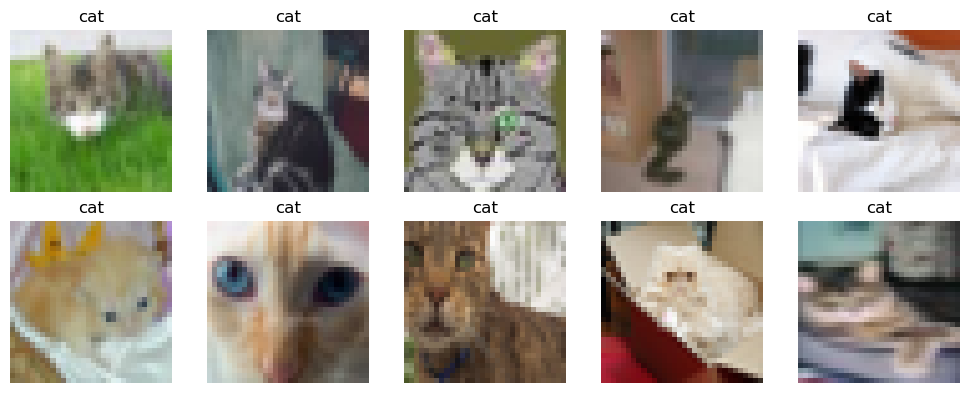

**예시 이미지:** CIFAR-10의 고양이 사진들. 해상도가 32×32이므로 이미지의 형태와 배경이 단순하지 않을 때는 특징을 구분하기 어려울 수 있다.

### 데이터 증식은 원본 데이터 수를 늘리는 것일까?

데이터 증식(data augmentation)은 이미지를 무작위로 변형해 **훈련 중 보게 되는 모습의 다양성**을 높이는 방법이다. 보통 매번 새로운 원본 사진을 수집하는 것은 아니며, 여러 에포크에서 같은 이미지가 다른 변형으로 제시될 수 있다.

| 증식 기법 | 의미 | 확인할 점 |
|---|---|---|
| `RandomFlip("horizontal")` | 좌우 반전 | 반전해도 클래스가 같은가? |
| `RandomRotation(0.10)` | 최대 ±36도 회전 | 객체의 형태가 유지되는가? |
| `RandomTranslation(0.10,0.10)` | 높이·너비의 최대 약 ±10% 이동 | 객체가 지나치게 잘리지 않는가? |
| `RandomZoom(0.07)` | 크기 변화 | 주요 부위가 잘리지 않는가? |
| `RandomContrast(0.5)` | 대비 변화 | 색·대비가 지나치게 왜곡되지 않는가? |

증식 기법은 **레이블의 의미가 유지되는 범위에서** 선택해야 한다. 훈련 중 증식을 사용하더라도 검증·테스트는 보통 **증식하지 않은 이미지**로 평가한다.

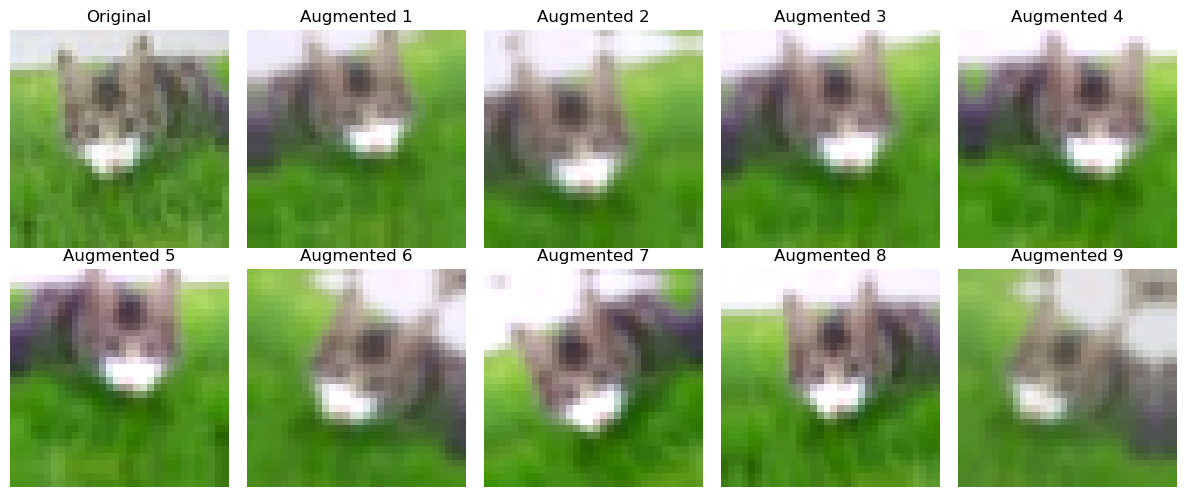

**데이터 증식 사례:** 동일한 고양이 사진에 반전·회전·이동·확대/축소 등의 무작위 변환을 여러 번 적용한 결과. 각 이미지는 **원본 고양이와 같은 클래스**다. 32×32 저해상도 이미지에서는 변형에 따라 디테일이 뭉개질 수 있다.

**비교:** 원본과 증식된 사진을 비교하면서 귀·얼굴처럼 분류에 중요한 부위가 남아 있는지 살펴보자. 변화가 크기만 하다고 좋은 증식은 아니다. 증식 강도는 검증 손실·정확도로 판단한다.

**작은 이미지에서 데이터 증식을 구성하는 예시**

```python
augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomZoom(0.07),
])
```

## 전이 학습과 미세 조정: 사전훈련 CNN 재사용하기

### 왜 새 CNN을 처음부터 훈련하지 않을까?

고양이·개 사진이 충분하지 않으면 큰 CNN을 처음부터 훈련했을 때 훈련 데이터에 과대적합하거나 유용한 시각적 특성을 제대로 학습하지 못할 수 있다. 대규모 이미지로 사전훈련된 CNN에는 **경계·질감·형태 등 다양한 이미지에서 재사용할 수 있는 특성**이 학습되어 있다.

이를 새로운 문제에 활용하는 방법은 크게 두 단계로 나눌 수 있다.

| 단계 | 사전훈련 CNN 기저(Base) | 새 분류층(Head) | 목적 |
|---|---|---|---|
| **① 특성 추출(전이 학습)** | 동결 | 훈련 | 기존 특성을 이용해 고양이·개 분류 학습 |
| **② 미세 조정** | 상위 일부 층만 훈련 | 계속 훈련 | 새로운 데이터에 맞게 일부 특성을 조정 |

**핵심 질문:** 두 단계에서 *어떤 층의 가중치가 바뀌는가?*

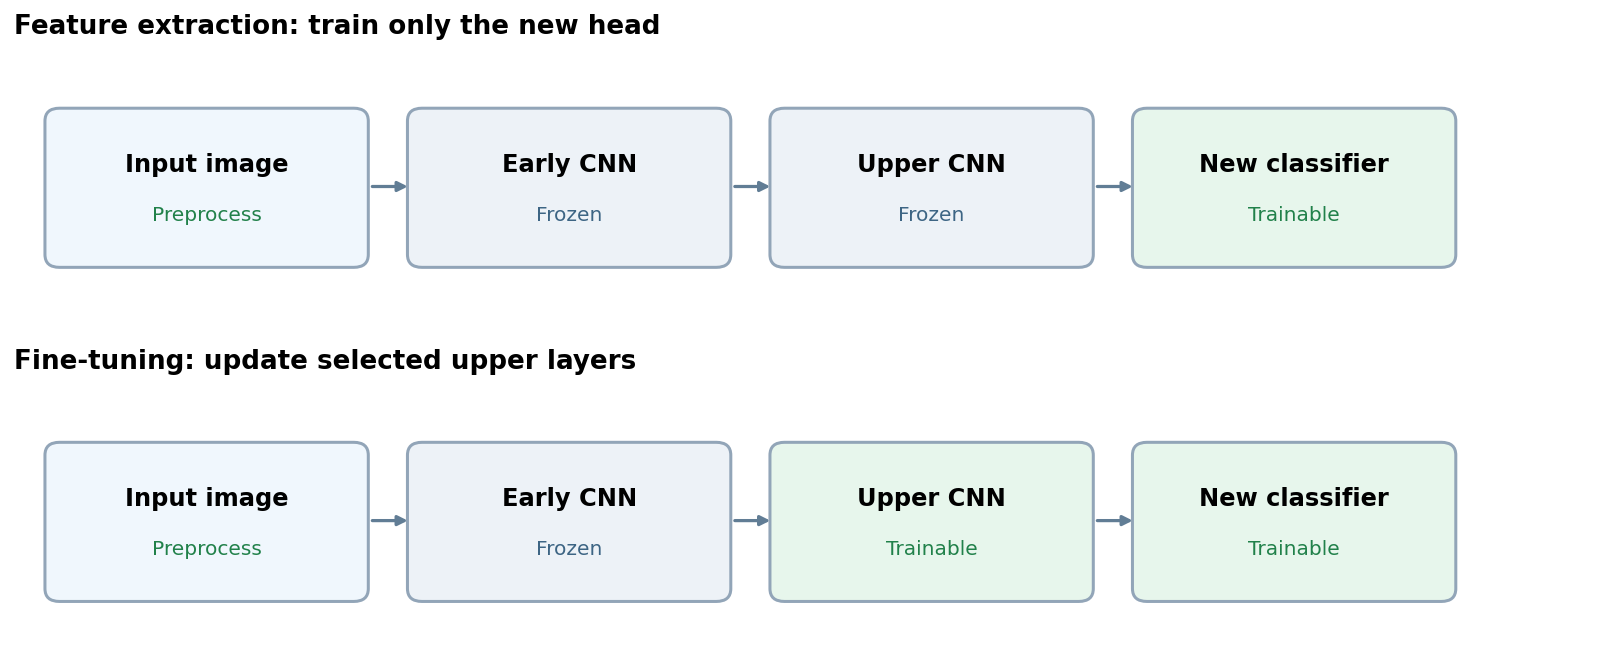

**그림 읽기:** 위쪽은 사전훈련 CNN 전체가 동결되고 새로운 분류층만 학습되는 단계다. 아래쪽은 CNN의 상위 일부 층도 학습하는 미세 조정 단계다. 파란 상자는 동결, 초록 상자는 훈련 가능을 뜻한다.

### ① 사전훈련된 Xception 기저 불러오기

Xception은 **채널 분리 합성곱, 배치 정규화, 잔차 연결**을 결합한 CNN이다. 여기서는 ImageNet으로 학습된 가중치를 불러와 *특성 추출*에 사용한다.

```python
transfer_base = keras.applications.Xception(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet",
)
transfer_base.trainable = False
```

- `weights="imagenet"`: 대규모 이미지 데이터로 사전훈련된 가중치를 사용한다.
- `include_top=False`: 원래의 ImageNet 분류 출력층을 제외하고 합성곱 기저만 사용한다.
- `trainable=False`: 기저 가중치가 현재 문제의 훈련 과정에서 바뀌지 않도록 한다.

CIFAR-10 이미지는 32×32이지만 여기에서는 Xception 입력 크기인 **96×96으로 확대**한다. 확대해도 원래 없던 세부 정보가 생기지는 않는다.

### ② 입력 전처리와 새 분류층 연결하기

이제 **32×32 RGB 이미지 → 96×96 확대 → 값 정규화 → Xception 기저 → 채널별 평균 → 고양이·개 확률** 순서로 연결한다.

```python
inputs = keras.Input(shape=(32, 32, 3))
x = layers.RandomFlip("horizontal")(inputs)
x = layers.Resizing(96, 96)(x)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)
x = transfer_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
transfer_model = keras.Model(inputs, outputs)
```

| 코드 | 의미 |
|---|---|
| `RandomFlip` | 훈련 중에만 좌우 반전을 무작위로 적용 |
| `Resizing` | 32×32 이미지를 96×96으로 확대 |
| `Rescaling` | 입력 픽셀값 0~255를 Xception에 맞는 **-1~1** 범위로 변환 |
| `transfer_base(..., training=False)` | 사전훈련 기저를 사용하되 **BatchNormalization은 추론 모드**로 처리 |
| `GlobalAveragePooling2D` | 특성맵의 공간 평균을 구해 채널별 값 하나로 요약 |
| `Dense(1, sigmoid)` | 고양이·개 이진 분류를 위한 출력층 |

**관찰:** 특성맵을 만드는 CNN 기저는 그대로 쓰고, **최종 분류 목적에 맞는 출력층만 새로 연결**한다.

### ③ 새 분류층만 훈련하기

기저를 동결한 상태에서 모델을 컴파일하고 새 분류층을 훈련한다.

```python
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

transfer_history = transfer_model.fit(
    catdog_x_train, catdog_y_train,
    validation_data=(catdog_x_val, catdog_y_val),
    epochs=4, batch_size=16,
)
```

- 훈련 데이터는 새 분류층의 가중치를 학습하는 데 사용한다.
- 검증 데이터는 새 이미지에서도 성능이 유지되는지 확인하는 데 사용한다.
- **이 단계에서는 사전훈련된 Xception 기저의 가중치가 업데이트되지 않는다.**

여기서 `catdog_x_train`, `catdog_y_train` 등은 고양이·개 이미지와 정답이 준비되어 있다고 가정한 변수다.

### ④ 미세 조정: 상위 일부 층을 추가로 훈련하기

새 분류층을 먼저 훈련한 다음, Xception 기저의 **상위 일부 층만 동결 해제**할 수 있다. 이때는 기존에 학습한 유용한 특성이 급격히 변하지 않도록 **작은 학습률**을 사용한다.

```python
transfer_base.trainable = True

# 마지막 20개 층만 훈련 대상 후보로 사용
for layer in transfer_base.layers[:-20]:
    layer.trainable = False

# BatchNormalization은 동결 상태로 유지
for layer in transfer_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# 훈련 가능 층을 바꿨으므로 다시 컴파일
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

fine_tune_history = transfer_model.fit(
    catdog_x_train, catdog_y_train,
    validation_data=(catdog_x_val, catdog_y_val),
    epochs=2, batch_size=16,
)
```

**주의:** 앞 단계에서 모델을 만들 때 사용한 `transfer_base(x, training=False)`는 그대로 유지한다. 이렇게 하면 미세 조정 중에도 BatchNormalization의 통계가 작은 배치에 의해 크게 흔들리는 것을 줄일 수 있다. `compile()`을 다시 호출하는 것도 중요하다.

### 전이 학습과 미세 조정의 결과는 어떻게 판단할까?

**질문:** 미세 조정을 하면 무조건 검증 정확도가 높아질까?

그렇지 않다. 더 많은 층을 훈련하면 새 데이터에 맞는 특성을 얻을 수도 있지만, 데이터가 적으면 오히려 과대적합하거나 사전훈련된 유용한 특성을 손상시킬 수 있다.

| 확인할 것 | 판단 기준 |
|---|---|
| 검증 손실·정확도 | 미세 조정 전보다 실제로 개선되었는가? |
| 훈련·검증 성능 차이 | 훈련 성능만 좋아진 것은 아닌가? |
| 학습률·동결 범위 | 너무 많은 가중치를 큰 학습률로 바꾸지 않았는가? |
| 최종 테스트 평가 | 모델 선택을 마친 뒤 별도 테스트셋에서 평가했는가? |

**정리:** 특성 추출과 미세 조정은 별개의 모델이 아니라, **같은 사전훈련 CNN을 새 문제에 맞춰 단계적으로 학습시키는 과정**이다.

## 객체 탐지: 이미지 분류를 넘어

### 컴퓨터 비전의 문제 유형

이미지가 같아도 **어떤 정답을 요구하는가**에 따라 컴퓨터 비전 문제는 달라진다. 먼저 아래 그림에서 각 모델이 어떤 결과를 출력해야 하는지 비교해 보자.

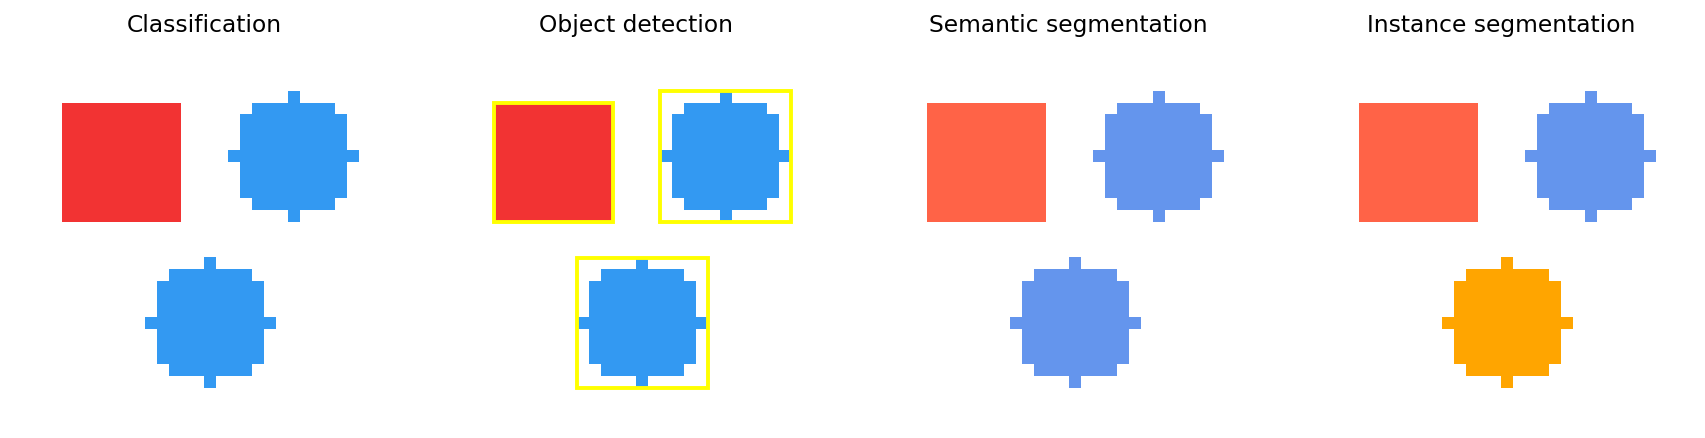

**그림 읽기:** 동일한 도형 이미지에 대해 (왼쪽부터) 이미지 분류, 객체 탐지, 시맨틱 분할, 인스턴스 분할의 **정답 형태**를 비교했다. 인공 도형으로 만든 설명용 예시이며 실제 모델의 예측 결과는 아니다.

**네 가지 문제의 출력은 어떻게 다른가?**

| 문제 | 모델이 답할 질문 | 출력 형태 |
|---|---|---|
| **이미지 분류** | 사진 전체에 무엇이 있는가? | 이미지당 클래스 점수 |
| **객체 탐지** | 무엇이 어디에 있는가? | 객체별 클래스·경계 상자·신뢰도 |
| **시맨틱 분할** | 각 픽셀은 어떤 클래스인가? | 픽셀별 클래스 레이블 |
| **인스턴스 분할** | 각 픽셀이 어떤 **개별 객체**에 속하는가? | 개별 객체별 마스크와 클래스 |

특히 그림의 **두 원**에 주목하자.

- 시맨틱 분할에서는 두 원이 같은 클래스이므로 **같은 색**을 갖는다.
- 인스턴스 분할에서는 클래스가 같아도 **서로 다른 개체**이므로 다른 색으로 구분한다.
- 객체 탐지에서는 원 각각을 감싸는 **경계 상자**를 예측하지만, 객체 내부의 모든 픽셀을 분류하지는 않는다.

**핵심:** 모델 구조를 선택하기 전에 **분류·탐지·분할 중 무엇을 예측해야 하는지** 먼저 정해야 한다.
여기서는 객체 탐지를 좀 더 자세히 소개한다.

### 객체 탐지: 물체의 종류와 위치를 함께 예측하기

객체 탐지는 이미지 분류처럼 클래스만 예측하는 것이 아니라 **객체별 위치**까지 예측한다. P3 실습의 Faster R-CNN은 두 단계를 구분하는 탐지 모델이다.

1. **ResNet-50 Backbone + FPN:** 이미지에서 다양한 크기의 객체를 표현할 특성맵을 만든다.
2. **RPN(1단계):** 물체가 있을 가능성이 높은 후보 영역을 제안한다.
3. **RoI Align + 탐지 헤드(2단계):** 후보 영역의 특성을 모아 클래스를 예측하고 경계 상자를 보정한다.
4. **후처리:** 중복된 예측 등을 정리하고 최종 결과를 출력한다.

최종 출력은 객체별 `boxes`, `labels`, `scores`다.

- `boxes`: `(x1, y1, x2, y2)` 형태의 경계 상자 좌표
- `labels`: 예측한 객체 클래스
- `scores`: 그 예측에 대한 모델의 신뢰도 점수

아래 실제 탐지 결과에서 **상자·클래스·점수**가 어디에 표시되는지 살펴보자.

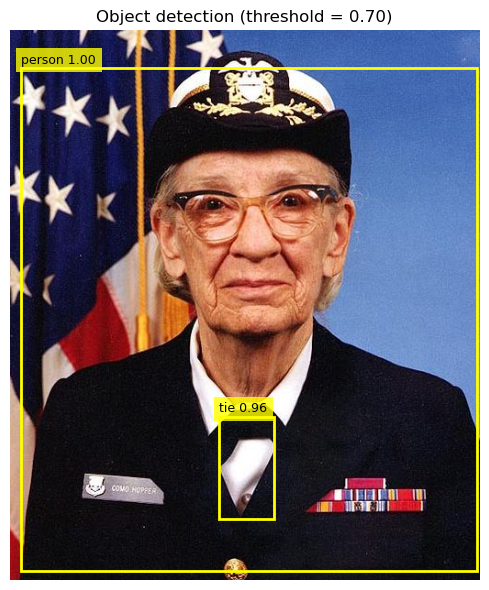

**관찰:** 탐지 결과는 이미지 전체에 대한 하나의 클래스가 아니라, 물체별 **위치(사각형)**와 **클래스·신뢰도(문자)**로 표시된다. 여러 객체를 한 이미지에서 탐지할 수 있다.

### 신뢰도 임곗값을 바꾸면 어떻게 될까?

모델은 여러 개의 후보를 출력할 수 있다. `score_threshold`는 이 중 **일정 점수 이상인 예측만 화면에 표시**하는 기준이다.

예를 들어 `score_threshold=0.30`과 `0.80`을 비교하면, 높은 임곗값에서는 보통 더 적은 후보가 남는다. 하지만 **높은 신뢰도라고 항상 정답은 아니며**, 실제 객체도 임곗값 아래라면 표시되지 않을 수 있다.

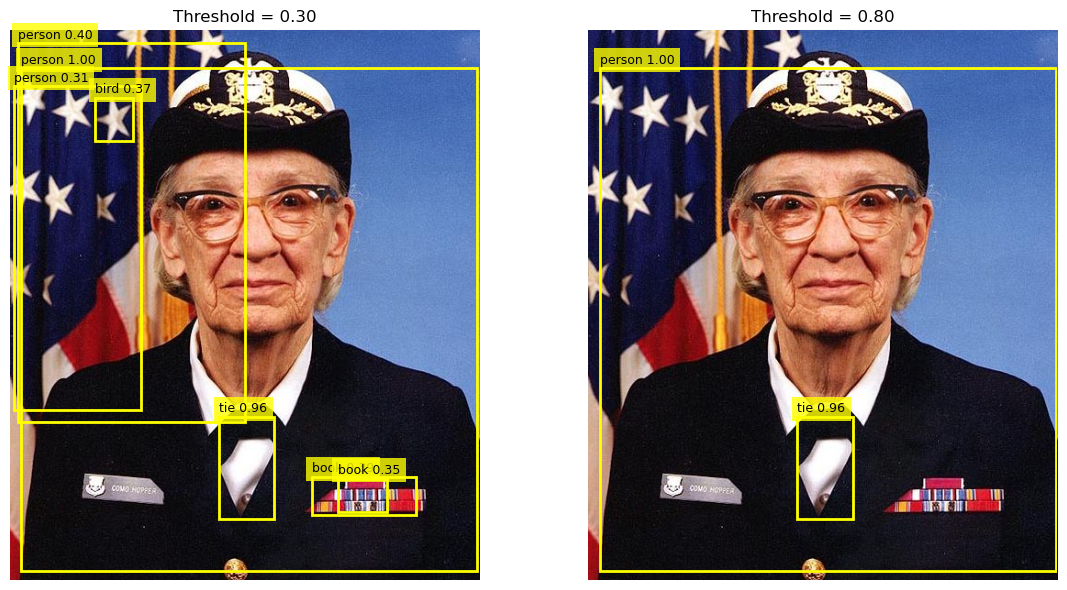

**비교:** 왼쪽은 임곗값 0.30, 오른쪽은 0.80이다. 낮은 임곗값에서 보이던 작은 후보 상자들이 높은 임곗값에서는 사라진다. **남은 상자의 개수만으로 모델의 정확성을 판단할 수는 없다.**

### 신뢰도

신뢰도(confidence score)는 객체 탐지 모델이 자신이 예측한 객체에 대해 얼마나 확신하는지를 나타내는 값이다.

객체를 탐지할 때마다 클래스, 경계 상자(Bounding Box), 신뢰도를 함께 계산된다.

예를 들어 다음과 같은 예측 결과가 있다고 하자.

| 예측 클래스   | 신뢰도  | 의미                       |
| -------- | ---- | ------------------------ |
| Elephant | 0.95 | 코끼리라는 예측에 대한 확신이 높음      |
| Zebra    | 0.80 | 얼룩말이라는 예측에 대한 확신이 비교적 높음 |
| Rhino    | 0.35 | 코뿔소라는 예측에 대한 확신이 낮음      |

신뢰도는 일반적으로 0\~1 사이의 값이며, 높을수록 모델이 해당 탐지를 더 확신한다는 의미다. 다만 신뢰도 0.95가 실제 정답일 확률이 정확히 95%라는 뜻은 아니다.

**신뢰도 기준**(Confidence Threshold)

객체 탐지에서는 신뢰도가 일정 수준 이상인 예측만 사용하도록 설정할 수 있다.

객체 탐지에서는 클래스만 맞는지가 아니라 **위치와 누락된 객체까지** 함께 확인해야 한다.
객체 탐지에서는 결과를 다음과 같이 구분한다.

| 구분 | 의미 | 예시 |
|---|---|---|
| **TP**(True Positive) | 올바르게 탐지한 객체 | 코끼리의 종류와 위치를 모두 올바르게 예측 |
| **FP**(False Positive) | 잘못 탐지한 결과 | 배경을 코끼리로 예측하거나 위치가 기준에 미달 |
| **FN**(False Negative) | 탐지하지 못한 실제 객체 | 사진에 있는 코끼리를 놓침 |

### 객체 탐지 성능 지표: mAP

이미지 분류 모델은 사진에 어떤 동물이 있는지 예측한다. 예를 들어 코끼리 사진을 보고 '코끼리'라고 올바르게 분류했다면 정답으로 평가할 수 있다.

하지만 **객체 탐지**(Object Detection)는 조금 더 복잡하다. 사진에 어떤 동물이 있는지뿐 아니라, **동물이 어디에 있는지도 찾아야 하기 때문**이다.

예를 들어 사진에 코끼리 2마리와 얼룩말 1마리가 있다면, 객체 탐지 모델은 세 동물의 종류와 위치를 각각 예측해야 한다.

따라서 객체 탐지 모델의 성능을 평가할 때는 다음 사항을 함께 고려해야 한다.

- **분류:** 동물의 종류를 올바르게 예측했는가?
- **위치:** 예측한 경계 상자(Bounding Box)가 실제 동물의 위치와 얼마나 일치하는가?
- **누락:** 사진에 있는 동물을 놓치지 않고 탐지했는가?
- **오탐:** 실제로 동물이 없는 곳을 동물이라고 잘못 탐지하지 않았는가?

이러한 객체 탐지 성능을 종합적으로 평가하는 대표적인 지표가 **mAP**(mean Average Precision)이다.

#### 정답 상자와 예측 상자가 얼마나 겹치는가? — IoU

객체 탐지 모델은 동물의 위치를 사각형의 경계 상자로 예측한다. 그런데 예측한 상자가 정답 상자와 정확히 일치하는 경우는 드물다.

따라서 두 상자가 얼마나 겹치는지를 측정할 필요가 있다. 이를 **IoU**(Intersection over Union)라고 한다.

$$
IoU = \frac{\text{두 상자가 겹치는 면적}}{\text{두 상자가 차지하는 전체 면적}}
$$

여기서 전체 면적은 두 상자의 합집합 면적을 의미한다.

- IoU = 1.0: 두 상자가 완전히 일치한다.
- IoU = 0.7: 두 상자가 상당히 많이 겹친다.
- IoU = 0.3: 두 상자가 일부만 겹친다.
- IoU = 0.0: 두 상자가 전혀 겹치지 않는다.

즉, **IoU가 클수록 모델이 예측한 상자의 위치가 정답에 가깝다.**

하지만 IoU가 어느 정도 이상이어야 올바른 탐지로 인정할 수 있을까? 이를 결정하기 위해 **IoU 기준값**(threshold)을 사용한다.

#### 어떤 예측을 올바른 탐지로 판단할까? — TP, FP, FN

예를 들어 IoU 기준을 0.50으로 설정했다고 하자.

모델이 코끼리를 탐지했을 때, 실제 코끼리의 정답 상자와 예측 상자의 IoU가 0.70이고 클래스도 올바르다면 성공적인 탐지로 판단할 수 있다.

반면 IoU가 0.30이라면 위치가 충분히 일치하지 않으므로 올바른 탐지로 인정하지 않는다.

객체 탐지에서는 결과를 다음과 같이 구분한다.

| 구분 | 의미 | 예시 |
|---|---|---|
| **TP**(True Positive) | 올바르게 탐지한 객체 | 코끼리의 종류와 위치를 모두 올바르게 예측 |
| **FP**(False Positive) | 잘못 탐지한 결과 | 배경을 코끼리로 예측하거나 위치가 기준에 미달 |
| **FN**(False Negative) | 탐지하지 못한 실제 객체 | 사진에 있는 코끼리를 놓침 |

여기서 주의할 점이 있다.

**하나의 실제 동물에는 하나의 예측 상자만 정탐**(TP)으로 연결될 수 있다. 동일한 동물에 여러 개의 상자를 예측했다고 해서 모두 정답으로 인정하지 않는다. 중복된 나머지 예측은 오탐(FP)이 된다.

또한 위치가 잘못된 예측은 FP가 되고, 그에 대응하는 실제 객체가 다른 예측과 연결되지 않았다면 FN도 발생한다.

따라서 좋은 객체 탐지 모델은 **정탐은 많고, 오탐과 미탐은 적어야 한다.**

#### 얼마나 정확하게 탐지하고, 얼마나 빠짐없이 찾아냈는가? — Precision과 Recall

객체 탐지 성능을 평가할 때는 두 가지 지표가 중요하다.

**Precision**(정밀도)은 모델이 탐지했다고 판단한 결과 중 실제로 올바른 탐지가 차지하는 비율이다.

$$
Precision = \frac{TP}{TP+FP}
$$

예를 들어 동물을 10번 탐지했는데 그중 8번이 올바른 탐지라면 Precision은 0.8이다.

**Recall**(재현율)은 실제로 존재하는 동물 중 모델이 올바르게 탐지한 비율이다.

$$
Recall = \frac{TP}{TP+FN}
$$

예를 들어 실제 동물이 10마리 있는데 그중 7마리만 올바르게 탐지했다면 Recall은 0.7이다.

즉, 두 지표는 서로 다른 질문에 답한다.

- **Precision:** 모델이 탐지한 결과를 얼마나 믿을 수 있는가?
- **Recall:** 실제 동물을 얼마나 빠짐없이 찾아냈는가?

그런데 Precision과 Recall은 모델의 **신뢰도**(confidence) 기준에 따라 달라질 수 있다.

예를 들어 신뢰도 기준을 높이면 모델이 확신하는 탐지만 남게 된다. 이 과정에서 잘못된 탐지가 줄어들 수 있지만, 실제 동물도 놓칠 수 있다.

반대로 신뢰도 기준을 낮추면 더 많은 동물을 찾아낼 수 있지만, 잘못된 탐지가 늘어날 수도 있다.

따라서 신뢰도 기준 하나에서 계산한 Precision이나 Recall만으로 모델의 전체 성능을 판단하기는 어렵다.

#### 여러 신뢰도 수준에서의 성능을 종합하면? — AP

**AP**(Average Precision)는 신뢰도 수준에 따라 달라지는 Precision과 Recall의 관계를 종합한 지표이다.

모델이 예측한 객체들을 신뢰도가 높은 순서대로 정렬하고, 예측을 하나씩 포함하면서 Precision과 Recall을 계산하면 **Precision–Recall 곡선**을 얻을 수 있다.

이 곡선에서 계산한 면적을 요약한 값이 AP이다. 실제 평가에서는 정해진 방식으로 Precision–Recall 곡선을 보간하여 AP를 계산한다.

AP는 **클래스별로 계산**한다.

예를 들어 African Wildlife 데이터셋에서는 다음과 같이 네 종류의 동물에 대해 각각 AP를 구할 수 있다.

| 동물 종류 | AP (가상 예시) |
|---|---:|
| Buffalo | 0.75 |
| Elephant | 0.85 |
| Rhino | 0.65 |
| Zebra | 0.95 |

이 값들은 설명을 위한 가상의 결과이며, 실제 P3 실험 결과는 아니다.

#### 클래스별 AP를 평균하면? — mAP

**mAP**(mean Average Precision)는 클래스별 AP를 평균한 값이다.

앞의 예시에서는 네 동물의 AP를 평균하면 다음과 같다.

$$
mAP = \frac{0.75+0.85+0.65+0.95}{4} = 0.80
$$

즉, 하나의 동물 종류만 잘 탐지하는 것이 아니라 **여러 종류의 동물을 전반적으로 얼마나 잘 탐지하는지** 평가할 수 있다.

단, AP를 계산할 때 적용하는 IoU 기준에 따라 mAP 값도 달라진다. 따라서 mAP를 보고할 때는 어떤 IoU 기준으로 평가했는지 함께 표시해야 한다.

### 확인 활동

1. IoU가 0.60인 예측 상자가 있다고 하자. 동물 종류가 올바르고 다른 예측과 중복 매칭되지 않았다면, IoU 기준이 0.50일 때와 0.75일 때 각각 정탐(TP)으로 인정될 수 있는가? 근거를 설명하라.
2. 신뢰도 기준을 높이면 Precision과 Recall은 각각 어떻게 달라질 수 있는가? 그 이유를 설명하라.

## CNN 아키텍처의 세 가지 개선 아이디어

CNN이 깊어지고 커질수록 **훈련의 안정성, 연산량, 정보 전달**이 중요해진다. 대표적인 설계 방법 세 가지는 다음과 같다.

1. **잔차 연결(Residual connection):** 중간 층을 건너뛰는 경로를 만든다.
2. **배치 정규화(Batch Normalization):** 중간 활성화의 분포를 정규화하고 학습 가능한 크기·이동 조정을 적용한다.
3. **채널 분리 합성곱(Depthwise Separable Convolution):** 공간 방향의 합성곱과 채널 간 결합을 분리한다.

세 방법은 해결하려는 문제가 서로 달라서 **하나의 아키텍처에서 함께 사용할 수 있다**.

### 잔차 연결: 입력 정보를 더하기

잔차 블록은 보통 다음 형태로 이해할 수 있다.

$$
y = F(x) + x
$$

- $F(x)$: 합성곱 등의 변환을 거친 출력
- $x$: 별도 경로로 전달된 입력
- $+$: 같은 위치의 값끼리 더하는 연산

입력과 출력의 높이·너비·채널 수가 같아야 직접 더할 수 있다. 다르면 `1×1` 합성곱 등의 투영 연산으로 모양을 맞출 수 있다.

잔차 연결은 깊은 네트워크에서 정보와 기울기가 전달될 수 있는 경로를 제공한다. 다만 **잔차 연결을 넣는 것만으로 성능 향상을 보장하는 것은 아니다**.

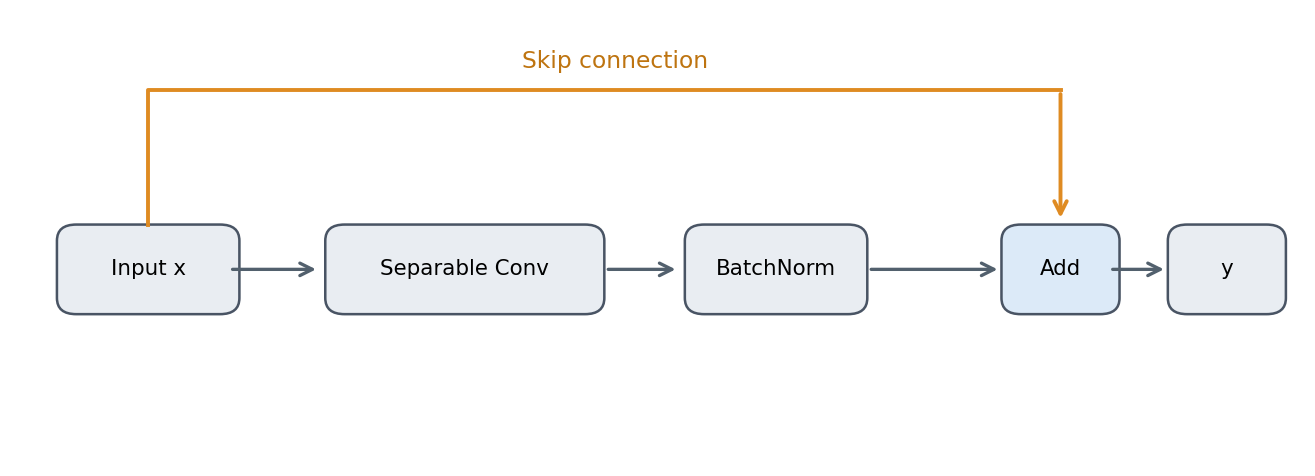

### 배치 정규화: 합성곱의 중간 출력 정규화

`BatchNormalization`은 훈련 배치의 통계 등을 사용해 중간 출력을 정규화하고, 학습 가능한 배율과 이동량을 적용한다. 학습 시와 추론 시의 통계 처리 방식이 다르다.

- **훈련 모드:** 배치의 평균·분산을 이용하고 이동 통계량을 갱신한다.
- **추론 모드:** 일반적으로 훈련 중 축적된 이동 평균·분산을 사용한다.

따라서 사전훈련된 Xception을 미세 조정할 때는 작은 데이터셋이나 작은 배치의 통계가 예측을 흔들 수 있으므로 **BatchNormalization을 동결하거나 추론 모드로 유지**하는 설계가 자주 사용된다.

배치 정규화는 **데이터의 픽셀을 [0,1]로 변환하는 입력 전처리**와 다른 작업이다.

### 채널 분리 합성곱: 연산을 두 단계로 나누기

일반적인 `Conv2D`는 공간상의 3×3 패턴과 채널 간 결합을 **한 번에** 학습한다. 채널 분리 합성곱은 두 단계로 나눈다.

1. **Depthwise convolution:** 입력 채널마다 독립적으로 공간 필터를 적용한다.
2. **Pointwise convolution:** `1×1` 합성곱으로 채널들을 결합하여 원하는 출력 채널 수를 만든다.

PyTorch에서는 `groups=in_channels`인 `nn.Conv2d`와 `kernel_size=1`인 `nn.Conv2d`의 조합으로 표현할 수 있다.

이 방식은 일반 합성곱보다 파라미터와 연산량을 줄일 수 있지만, **항상 정확도가 더 높은 것은 아니다**.

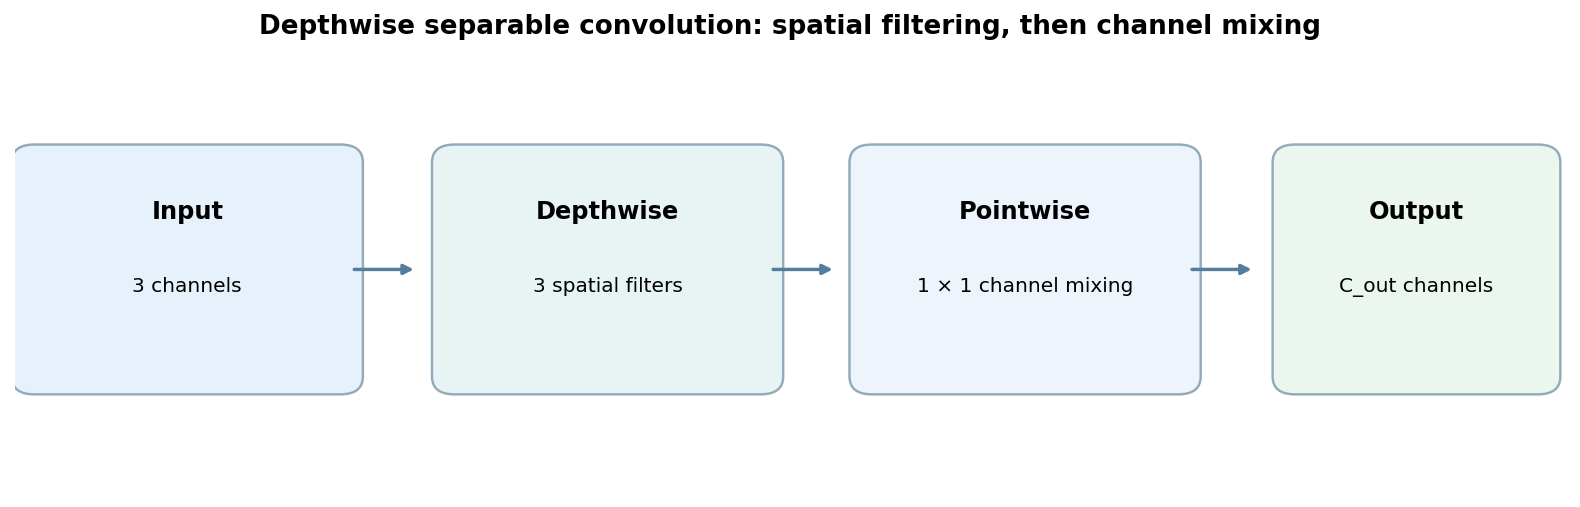

**관찰:** Depthwise 합성곱은 각 입력 채널에서 공간 필터를 따로 적용하고, Pointwise의 `1×1` 합성곱은 채널을 결합해 새로운 출력 채널을 만든다.

### 파라미터 수를 비교하면?

입력 채널 32개를 출력 채널 64개로 바꾸는 3×3 합성곱(편향 제외)을 가정한다.

- **일반 합성곱:** $3\times3\times32\times64 = 18,432$
- **Depthwise:** $3\times3\times32 = 288$
- **Pointwise:** $1\times1\times32\times64 = 2,048$
- **채널 분리 합성곱 합계:** $288+2,048 = 2,336$

같은 입력·출력 채널 수라도 내부 계산 구조가 달라 파라미터 수가 크게 줄어든다.

In [3]:
# 일반 합성곱과 채널 분리 합성곱(편향 제외) 비교
C_in, C_out, k = 32, 64, 3
regular_count = k*k*C_in*C_out
separable_count = k*k*C_in + C_in*C_out
print('Regular Conv2D:', regular_count)
print('Depthwise + pointwise:', separable_count)
print('Ratio:', round(separable_count / regular_count, 3))
assert (regular_count, separable_count) == (18432, 2336)

Regular Conv2D: 18432
Depthwise + pointwise: 2336
Ratio: 0.127


### Xception: 세 가지 방법을 하나의 모델에 결합

Xception은 많은 `SeparableConv2D` 층과 `BatchNormalization`, `Add`로 이루어진 잔차 연결을 사용한다. 모델의 큰 흐름은 다음과 같다.

| 부분 | 역할 |
|---|---|
| **Entry Flow** | 초기 합성곱과 다운샘플링으로 기본 특성 추출 |
| **Middle Flow** | 채널 분리 합성곱과 잔차 연결 블록을 **8회 반복**해 특징을 변환 |
| **Exit Flow** | 더 고수준의 특징을 추출하고 마지막 특성맵을 출력 |

전체 Xception을 이해할 때 모든 층 이름을 외울 필요는 없다. **한 블록의 주 경로에서 특성을 변환하고, 건너뛰기 경로로 입력 정보를 전달해 더한다**는 구조가 핵심이다.

**주의:** Xception을 단순화한 교육용 PyTorch 모델은 세 가지 설계 아이디어를 확인하기 위한 모델이며, ImageNet 사전훈련 Xception의 전체 층 구성이나 가중치를 복제한 모델은 아니다.

## 핵심 정리

- **Conv2D:** 필터가 국소 영역의 픽셀값과 가중치를 곱해 더하고, 같은 필터를 여러 위치에 반복 적용하여 특성맵을 만든다.
- **입력 채널:** 필터 하나의 깊이를 결정한다. RGB 입력의 3×3 필터 하나는 `3×3×3` 가중치를 갖는다.
- **필터 수:** 출력 채널 수를 결정한다. 필터 32개라면 출력 특성맵 32개다.
- **패딩·보폭:** 출력의 **높이와 너비**를 결정한다. `same`도 보폭 2에서는 공간 크기를 줄인다.
- **가중치 공유:** 파라미터 수를 줄이고 동일한 국소 패턴을 여러 위치에서 찾을 수 있게 한다.
- **풀링:** 각 채널의 공간 정보를 요약하며, 학습할 필터 가중치는 없다.
- **데이터 증식:** 훈련 중 이미지의 다양성을 높이고, 검증·테스트에서 일반화를 확인한다.
- **전이 학습·미세 조정:** 사전훈련된 CNN의 특성을 재사용하고, 필요할 때 상위 일부 층을 조정한다.
- **컴퓨터 비전:** 분류는 클래스, 탐지는 클래스·경계 상자, 분할은 픽셀 또는 인스턴스 단위의 출력을 다룬다.
- **Xception:** 채널 분리 합성곱·배치 정규화·잔차 연결을 결합한 CNN이다.

## 확인 문제

1. 흑백 이미지 `(28,28,1)`에 `Conv2D(32,3,padding="same")`을 적용하면 출력 모양은 무엇인가?
2. RGB 이미지에 `3×3` 필터 **하나**를 적용하면 가중치는 몇 개인가? (편향 제외)
3. `filters=64`는 무엇을 의미하며 출력 텐서에 어떤 영향을 주는가?
4. 입력 `7×7`, 필터 `3×3`, `padding="valid"`, `strides=2`이면 출력의 공간 크기는?
5. `padding="same"`, `strides=2`를 쓰면 입력의 공간 크기가 반드시 유지되는가?
6. `Conv2D(32,3)`에서 입력 이미지의 크기만 바꾸면 가중치 수가 달라지는가?
7. `MaxPooling2D(2)`에서 입력 `(14,14,64)`의 출력 크기는?
8. `GlobalAveragePooling2D()`에 `(7,7,128)`이 들어가면 출력은 몇 차원인가?
9. 전이 학습에서 Xception의 `include_top=False`, `trainable=False`는 각각 무엇을 뜻하는가?
10. 객체 탐지와 이미지 분류의 출력 타깃은 어떻게 다른가?
11. 시맨틱 분할과 인스턴스 분할은 같은 클래스의 객체 둘을 어떻게 다루는가?
12. Xception에서 채널 분리 합성곱, 배치 정규화, 잔차 연결은 각각 어떤 역할을 하는가?